<a href="https://colab.research.google.com/github/koushiksarabada31/DEEP-LEARNING-/blob/main/Skill/Skill_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

print("PyTorch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Selected Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected. Running on CPU.")


PyTorch Version: 2.14.1+cu130
CUDA Available: True
Selected Device: cuda
GPU Name: Tesla T4


In [2]:

class GPUInferenceModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Flatten(),
            nn.Linear(32 * 32 * 32, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = GPUInferenceModel().to(device)
model.eval()

print("CNN Model Created Successfully")
print("Model Device:", device)


CNN Model Created Successfully
Model Device: cuda


In [3]:

BATCH_SIZE = 32
IMAGE_SIZE = 128
NUM_RUNS = 20

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()


def measure_gpu(function):
    if device.type == "cuda":
        start = torch.cuda.Event(enable_timing=True)
        end = torch.cuda.Event(enable_timing=True)

        start.record()
        result = function()
        end.record()

        synchronize()
        return start.elapsed_time(end), result

    start_time = time.perf_counter()
    result = function()
    elapsed = (time.perf_counter() - start_time) * 1000
    return elapsed, result


# Warm-up GPU
dummy = torch.randn(
    BATCH_SIZE, 3, IMAGE_SIZE, IMAGE_SIZE
).to(device)

with torch.no_grad():
    for _ in range(5):
        model(dummy)

synchronize()

results = []

for run in range(NUM_RUNS):

    # 1. CPU PREPROCESSING
    start = time.perf_counter()

    images = np.random.randint(
        0, 256,
        (BATCH_SIZE, IMAGE_SIZE, IMAGE_SIZE, 3),
        dtype=np.uint8
    )

    images = images.astype(np.float32) / 255.0
    images = np.transpose(images, (0, 3, 1, 2)).copy()

    cpu_tensor = torch.from_numpy(images)

    preprocess_time = (time.perf_counter() - start) * 1000

    # 2. HOST TO DEVICE TRANSFER
    synchronize()
    start = time.perf_counter()

    gpu_tensor = cpu_tensor.to(device)

    synchronize()
    h2d_time = (time.perf_counter() - start) * 1000

    # 3. GPU KERNEL EXECUTION
    with torch.no_grad():
        compute_time, output = measure_gpu(
            lambda: model(gpu_tensor)
        )

    # 4. DEVICE TO HOST TRANSFER
    synchronize()
    start = time.perf_counter()

    cpu_output = output.cpu().numpy()

    d2h_time = (time.perf_counter() - start) * 1000

    # 5. CPU POSTPROCESSING
    start = time.perf_counter()

    probabilities = np.exp(
        cpu_output - np.max(cpu_output, axis=1, keepdims=True)
    )

    probabilities /= np.sum(
        probabilities, axis=1, keepdims=True
    )

    predictions = np.argmax(probabilities, axis=1)

    postprocess_time = (time.perf_counter() - start) * 1000

    results.append({
        "Run": run + 1,
        "CPU Preprocessing": preprocess_time,
        "H2D Transfer": h2d_time,
        "GPU Kernel": compute_time,
        "D2H Transfer": d2h_time,
        "CPU Postprocessing": postprocess_time
    })

print("GPU Inference Pipeline Executed Successfully!")
print("Total Runs:", NUM_RUNS)
print("Predictions:", predictions[:10])


GPU Inference Pipeline Executed Successfully!
Total Runs: 20
Predictions: [9 9 9 9 9 9 9 9 9 9]


In [4]:

df = pd.DataFrame(results)

print("EXECUTION TRACE")
display(df.round(3))

stage_columns = [
    "CPU Preprocessing",
    "H2D Transfer",
    "GPU Kernel",
    "D2H Transfer",
    "CPU Postprocessing"
]

average_times = df[stage_columns].mean()

print("\nAVERAGE EXECUTION TIME")
display(average_times.round(3).to_frame("Time (ms)"))

print("Total Pipeline Time:",
      round(average_times.sum(), 3), "ms")


EXECUTION TRACE


,Run,CPU Preprocessing,H2D Transfer,GPU Kernel,D2H Transfer,CPU Postprocessing
0,1,11.810,1.957,3.032,0.158,1.254
1,2,11.392,1.953,2.990,0.087,0.102
2,3,7.335,1.738,3.032,0.112,0.141
3,4,8.347,1.619,2.946,0.086,0.113
4,5,5.741,1.453,2.927,0.079,0.099
5,6,5.468,1.667,2.968,0.072,0.114
6,7,4.977,1.417,2.918,0.071,0.110
7,8,5.475,1.411,2.906,0.085,0.101
8,9,5.611,1.454,2.914,0.072,0.100
9,10,5.070,1.394,2.956,0.070,0.099



AVERAGE EXECUTION TIME


,Time (ms)
CPU Preprocessing,6.194
H2D Transfer,1.522
GPU Kernel,2.934
D2H Transfer,0.081
CPU Postprocessing,0.162


Total Pipeline Time: 10.893 ms


In [5]:

service_time = average_times.sum()

NUM_REQUESTS = 10
ARRIVAL_INTERVAL = service_time * 0.5

arrival_times = [
    i * ARRIVAL_INTERVAL for i in range(NUM_REQUESTS)
]

start_times = []
finish_times = []
queue_times = []

previous_finish = 0

for arrival in arrival_times:

    start = max(arrival, previous_finish)
    finish = start + service_time

    queue = start - arrival

    start_times.append(start)
    finish_times.append(finish)
    queue_times.append(queue)

    previous_finish = finish

queue_df = pd.DataFrame({
    "Request": range(1, NUM_REQUESTS + 1),
    "Arrival Time (ms)": arrival_times,
    "Start Time (ms)": start_times,
    "Finish Time (ms)": finish_times,
    "Queue Time (ms)": queue_times
})

print("SERVING QUEUE ANALYSIS")
display(queue_df.round(3))

print("Average Queue Time:",
      round(np.mean(queue_times), 3), "ms")


SERVING QUEUE ANALYSIS


,Request,Arrival Time (ms),Start Time (ms),Finish Time (ms),Queue Time (ms)
0,1,0.000,0.000,10.893,0.000
1,2,5.446,10.893,21.786,5.446
2,3,10.893,21.786,32.679,10.893
3,4,16.339,32.679,43.571,16.339
4,5,21.786,43.571,54.464,21.786
5,6,27.232,54.464,65.357,27.232
6,7,32.679,65.357,76.250,32.679
7,8,38.125,76.250,87.143,38.125
8,9,43.571,87.143,98.036,43.571
9,10,49.018,98.036,108.929,49.018


Average Queue Time: 24.509 ms


In [6]:

avg_queue = np.mean(queue_times)

bottleneck_data = {
    "Stage": [
        "CPU Preprocessing",
        "H2D Transfer",
        "GPU Kernel Execution",
        "D2H Transfer",
        "CPU Postprocessing",
        "Serving Queue"
    ],

    "Delay Type": [
        "Data Related",
        "Memory Transfer",
        "Compute Related",
        "Memory Transfer",
        "Data Related",
        "Serving Related"
    ],

    "Time (ms)": [
        average_times["CPU Preprocessing"],
        average_times["H2D Transfer"],
        average_times["GPU Kernel"],
        average_times["D2H Transfer"],
        average_times["CPU Postprocessing"],
        avg_queue
    ]
}

bottleneck_df = pd.DataFrame(bottleneck_data)

total_delay = bottleneck_df["Time (ms)"].sum()

bottleneck_df["Percentage (%)"] = (
    bottleneck_df["Time (ms)"] / total_delay
) * 100

print("SYSTEM-LEVEL BOTTLENECK MAP")
display(bottleneck_df.round(3))

main_bottleneck = bottleneck_df.loc[
    bottleneck_df["Time (ms)"].idxmax()
]

print("\nMAIN BOTTLENECK:", main_bottleneck["Stage"])
print("DELAY CATEGORY:", main_bottleneck["Delay Type"])
print("TIME:", round(main_bottleneck["Time (ms)"], 3), "ms")


SYSTEM-LEVEL BOTTLENECK MAP


,Stage,Delay Type,Time (ms),Percentage (%)
0,CPU Preprocessing,Data Related,6.194,17.496
1,H2D Transfer,Memory Transfer,1.522,4.299
2,GPU Kernel Execution,Compute Related,2.934,8.289
3,D2H Transfer,Memory Transfer,0.081,0.228
4,CPU Postprocessing,Data Related,0.162,0.457
5,Serving Queue,Serving Related,24.509,69.231



MAIN BOTTLENECK: Serving Queue
DELAY CATEGORY: Serving Related
TIME: 24.509 ms


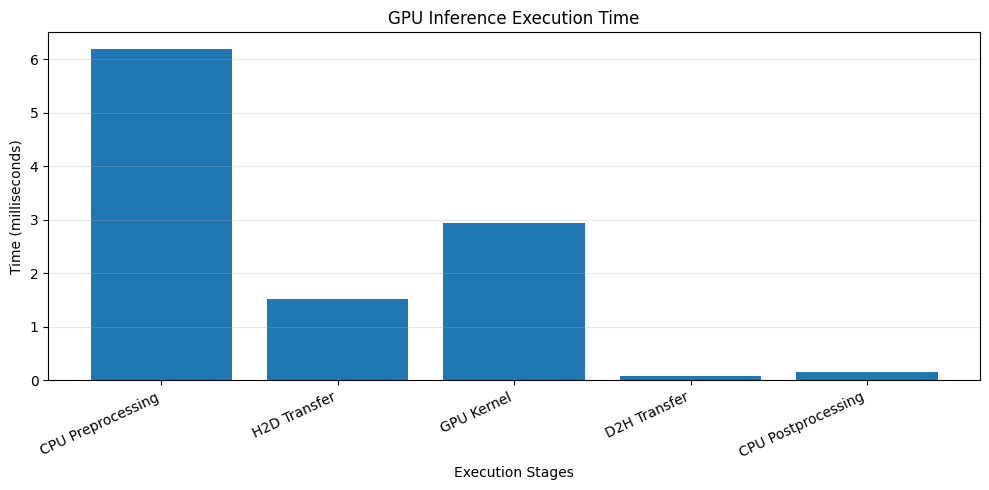

In [7]:

plt.figure(figsize=(10, 5))

plt.bar(
    average_times.index,
    average_times.values
)

plt.title("GPU Inference Execution Time")
plt.xlabel("Execution Stages")
plt.ylabel("Time (milliseconds)")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


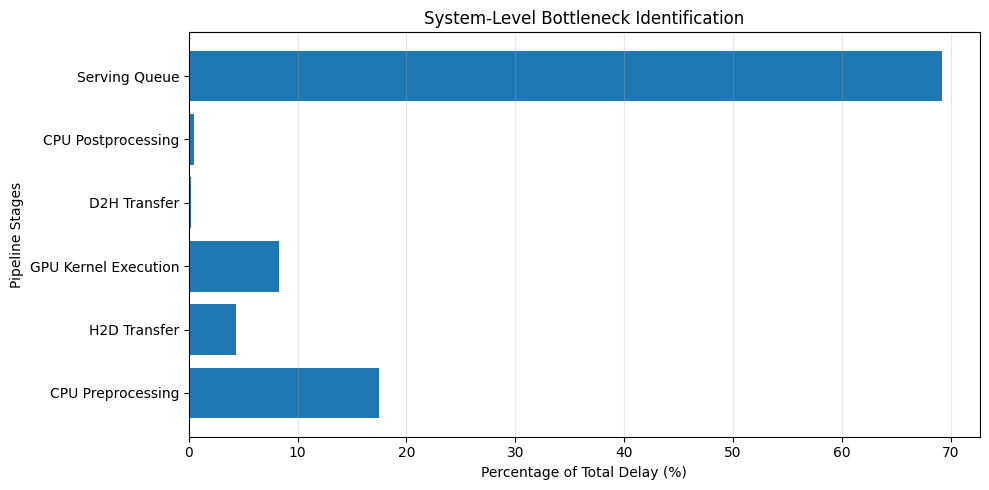

In [8]:

plt.figure(figsize=(10, 5))

plt.barh(
    bottleneck_df["Stage"],
    bottleneck_df["Percentage (%)"]
)

plt.title("System-Level Bottleneck Identification")
plt.xlabel("Percentage of Total Delay (%)")
plt.ylabel("Pipeline Stages")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [9]:

print("========== GPU INFERENCE ANALYSIS ==========")

print("\nDevice:", device)
print("Total Runs:", NUM_RUNS)
print("Batch Size:", BATCH_SIZE)

print("\nAverage Pipeline Time:",
      round(average_times.sum(), 3), "ms")

print("Average Serving Queue Time:",
      round(avg_queue, 3), "ms")

print("\nIdentified Bottleneck:")
print(main_bottleneck["Stage"])

print("\nRecommended Optimization:")

recommendations = {
    "CPU Preprocessing": "Optimize image preprocessing and parallelize CPU operations.",
    "H2D Transfer": "Use pinned memory and optimize data transfer.",
    "GPU Kernel Execution": "Optimize GPU kernels and use efficient batching.",
    "D2H Transfer": "Reduce unnecessary data transfers to CPU.",
    "CPU Postprocessing": "Optimize CPU-side prediction processing.",
    "Serving Queue": "Improve request scheduling and increase serving capacity."
}

print(recommendations[main_bottleneck["Stage"]])

print("\n========== ANALYSIS COMPLETED ==========")


========== GPU INFERENCE ANALYSIS ==========

Device: cuda
Total Runs: 20
Batch Size: 32

Average Pipeline Time: 10.893 ms
Average Serving Queue Time: 24.509 ms

Identified Bottleneck:
Serving Queue

Recommended Optimization:
Improve request scheduling and increase serving capacity.

========== ANALYSIS COMPLETED ==========
